In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
df = pd.read_csv("car data.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [8]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(2)

In [10]:
df.dtypes

Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
dtype: object

In [11]:
Q1 = df['Selling_Price'].quantile(0.25)
Q3 = df['Selling_Price'].quantile(0.75)

IQR = Q3 - Q1

outliers = df[(df['Selling_Price'] < Q1 - 1.5 * IQR) |
              (df['Selling_Price'] > Q3 + 1.5 * IQR)]

print("Number of outliers:", len(outliers))
print(outliers)

Number of outliers: 17
         Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
50       fortuner  2012          14.90          30.61      104707    Diesel   
51       fortuner  2015          23.00          30.61       40000    Diesel   
52         innova  2017          18.00          19.77       15000    Diesel   
53       fortuner  2013          16.00          30.61      135000    Diesel   
59       fortuner  2014          19.99          35.96       41000    Diesel   
62       fortuner  2014          18.75          35.96       78000    Diesel   
63       fortuner  2015          23.50          35.96       47000    Diesel   
64       fortuner  2017          33.00          36.23        6000    Diesel   
66         innova  2017          19.75          23.15       11000    Petrol   
69  corolla altis  2016          14.25          20.91       12000    Petrol   
79       fortuner  2012          14.50          30.61       89000    Diesel   
80  corolla altis  2016      

In [12]:
df = df.drop('Car_Name', axis=1)
df = pd.get_dummies(df, drop_first=True, dtype=int)
df.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,2014,3.35,5.59,27000,0,0,1,0,1
1,2013,4.75,9.54,43000,0,1,0,0,1
2,2017,7.25,9.85,6900,0,0,1,0,1
3,2011,2.85,4.15,5200,0,0,1,0,1
4,2014,4.60,6.87,42450,0,1,0,0,1


In [13]:
X = df.drop('Selling_Price', axis=1)
y = df['Selling_Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [14]:
lr = LinearRegression()
dt = DecisionTreeRegressor(random_state=42)
rf = RandomForestRegressor(random_state=42)

lr.fit(X_train_scaled, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [15]:
p1 = lr.predict(X_test_scaled)
p2 = dt.predict(X_test)
p3 = rf.predict(X_test)

In [16]:
print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, p1))
print("MSE:", mean_squared_error(y_test, p1))
print("RMSE:", mean_squared_error(y_test, p1) ** 0.5)
print("R2 Score:", r2_score(y_test, p1))

print("\nDecision Tree")
print("MAE:", mean_absolute_error(y_test, p2))
print("MSE:", mean_squared_error(y_test, p2))
print("RMSE:", mean_squared_error(y_test, p2) ** 0.5)
print("R2 Score:", r2_score(y_test, p2))

print("\nRandom Forest")
print("MAE:", mean_absolute_error(y_test, p3))
print("MSE:", mean_squared_error(y_test, p3))
print("RMSE:", mean_squared_error(y_test, p3) ** 0.5)
print("R2 Score:", r2_score(y_test, p3))

Linear Regression
MAE: 1.2162256821297062
MSE: 3.4788039706379017
RMSE: 1.865155213551382
R2 Score: 0.8489813024899067

Decision Tree
MAE: 0.8452459016393442
MSE: 2.008659016393443
RMSE: 1.4172716805162808
R2 Score: 0.912801908081639

Random Forest
MAE: 0.5915852459016395
MSE: 0.8009135336065566
RMSE: 0.8949377261053176
R2 Score: 0.9652314646975381


In [17]:
scores = [r2_score(y_test, p1),
          r2_score(y_test, p2),
          r2_score(y_test, p3)]

models = ['Linear Regression', 'Decision Tree', 'Random Forest']

print("Best Model:", models[scores.index(max(scores))])

Best Model: Random Forest


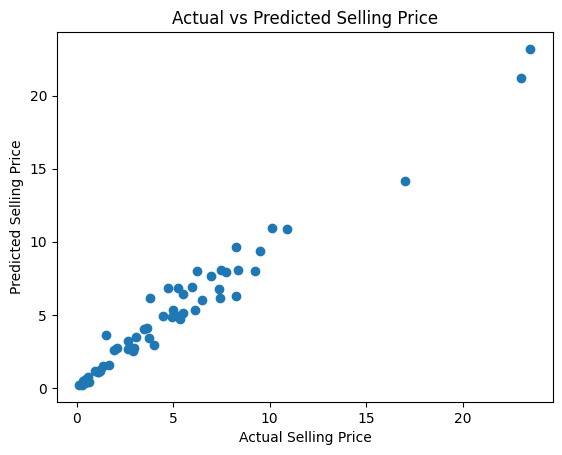

In [18]:
best = scores.index(max(scores))
predictions = [p1, p2, p3]

plt.scatter(y_test, predictions[best])
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")
plt.show()

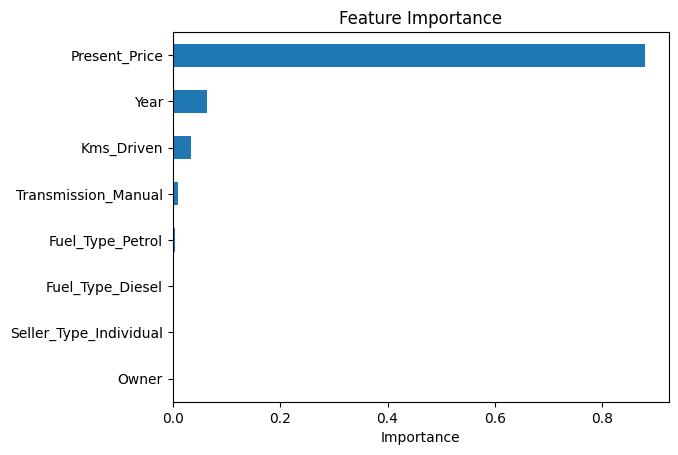

Owner                     0.002190
Seller_Type_Individual    0.002500
Fuel_Type_Diesel          0.003004
Fuel_Type_Petrol          0.003655
Transmission_Manual       0.009715
Kms_Driven                0.034822
Year                      0.064431
Present_Price             0.879682
dtype: float64


In [19]:
importance = pd.Series(rf.feature_importances_, index=X.columns)

importance.sort_values().plot(kind='barh')
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

print(importance.sort_values(ascending=True))

Insights

In this daatset we predicted used car selling prices using Linear Regression, Decision Tree, and Random Forest algorithms. Among the three models, Decision Tree Regressor performed the best with an R² score of approximately 83.96%. Present price was the most influential feature in predicting selling price. Using this datastet we predicted which used car had most high selling prices based on other properties.
